In [17]:
# %pip install "kagglehub[pandas-datasets]" pandas numpy matplotlib seaborn scikit-learn


In [18]:
#import all required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub as kh
from pathlib import Path
from matplotlib.ticker import FuncFormatter, MaxNLocator
import matplotlib.dates as mdates

In [19]:
#reading the csv file
df = pd.read_csv('../figures/Housing.csv')

In [20]:
df.head

<bound method NDFrame.head of                id             date     price  bedrooms  bathrooms  \
0      7229300521  20141013T000000  231300.0         2       1.00   
1      6414100192  20141209T000000  538000.0         3       2.25   
2      5631500400  20150225T000000  180000.0         2       1.00   
3      2487200875  20141209T000000  604000.0         4       3.00   
4      1954400510  20150218T000000  510000.0         3       2.00   
...           ...              ...       ...       ...        ...   
21608   263000018  20140521T000000  360000.0         3       2.50   
21609  6600060120  20150223T000000  400000.0         4       2.50   
21610  1523300141  20140623T000000  402101.0         2       0.75   
21611   291310100  20150116T000000  400000.0         3       2.50   
21612  1523300157  20141015T000000  325000.0         2       0.75   

       sqft_living  sqft_lot  floors  waterfront  view  ...  grade  \
0             1180      5650     1.0           0     0  ...      7   
1

In [21]:
#info
df.info

<bound method DataFrame.info of                id             date     price  bedrooms  bathrooms  \
0      7229300521  20141013T000000  231300.0         2       1.00   
1      6414100192  20141209T000000  538000.0         3       2.25   
2      5631500400  20150225T000000  180000.0         2       1.00   
3      2487200875  20141209T000000  604000.0         4       3.00   
4      1954400510  20150218T000000  510000.0         3       2.00   
...           ...              ...       ...       ...        ...   
21608   263000018  20140521T000000  360000.0         3       2.50   
21609  6600060120  20150223T000000  400000.0         4       2.50   
21610  1523300141  20140623T000000  402101.0         2       0.75   
21611   291310100  20150116T000000  400000.0         3       2.50   
21612  1523300157  20141015T000000  325000.0         2       0.75   

       sqft_living  sqft_lot  floors  waterfront  view  ...  grade  \
0             1180      5650     1.0           0     0  ...      7   

In [22]:
# information in columns
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,21613.0,NaN,NaN,NaN,4580306147.70999,2876569751.888581,1000102.0,2123049194.0,3904930410.0,7308900445.0,9900000190.0
date,21613,372,20140623T000000,142,NaN,NaN,NaN,NaN,NaN,NaN,NaN
price,21613.0,NaN,NaN,NaN,540088.57669,367126.825086,75000.0,321950.0,450000.0,645000.0,7700000.0
bedrooms,21613.0,NaN,NaN,NaN,3.370795,0.930105,0.0,3.0,3.0,4.0,33.0
bathrooms,21613.0,NaN,NaN,NaN,2.114757,0.770163,0.0,1.75,2.25,2.5,8.0
sqft_living,21613.0,NaN,NaN,NaN,2079.899736,918.440897,290.0,1427.0,1910.0,2550.0,13540.0
sqft_lot,21613.0,NaN,NaN,NaN,15106.967566,41420.511515,520.0,5040.0,7618.0,10688.0,1651359.0
floors,21613.0,NaN,NaN,NaN,1.494309,0.539989,1.0,1.0,1.5,2.0,3.5
waterfront,21613.0,NaN,NaN,NaN,0.007542,0.086517,0.0,0.0,0.0,0.0,1.0
view,21613.0,NaN,NaN,NaN,0.234303,0.766318,0.0,0.0,0.0,0.0,4.0


In [23]:
# finding columns to remove
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 21613 entries, 0 to 21612
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             21613 non-null  int64  
 1   date           21613 non-null  str    
 2   price          21613 non-null  float64
 3   bedrooms       21613 non-null  int64  
 4   bathrooms      21613 non-null  float64
 5   sqft_living    21613 non-null  int64  
 6   sqft_lot       21613 non-null  int64  
 7   floors         21613 non-null  float64
 8   waterfront     21613 non-null  int64  
 9   view           21613 non-null  int64  
 10  condition      21613 non-null  int64  
 11  grade          21613 non-null  int64  
 12  sqft_above     21613 non-null  int64  
 13  sqft_basement  21613 non-null  int64  
 14  yr_built       21613 non-null  int64  
 15  yr_renovated   21613 non-null  int64  
 16  zipcode        21613 non-null  int64  
 17  lat            21613 non-null  float64
 18  long           21

## 01 Data Cleaning

In [24]:
#create a copy to edit and work with
df_clean = df.copy()

### 1.1 Empty Columns

All columns have 21613 non-null values therefore none need to be deleted at this stage. 

### 1.2 Missing Values

None of the rows have missing values therefore none need to be deleted at this stage. 

In [25]:
df.isnull().sum(axis=1)

0        0
1        0
2        0
3        0
4        0
        ..
21608    0
21609    0
21610    0
21611    0
21612    0
Length: 21613, dtype: int64

In [26]:
df[df.isnull().sum(axis=1) > 0]

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15


### 1.3 Duplicates

The data has no duplicates

In [27]:
#checking and removing duplicates
n_duplicates = df_clean.duplicated().sum()
print(n_duplicates)
df_clean = df.drop_duplicates()

0


### 1.4 Reformatting

The price has no currency sign and commas. 

### 1.5 Outliers    

Finding outliers in the price.

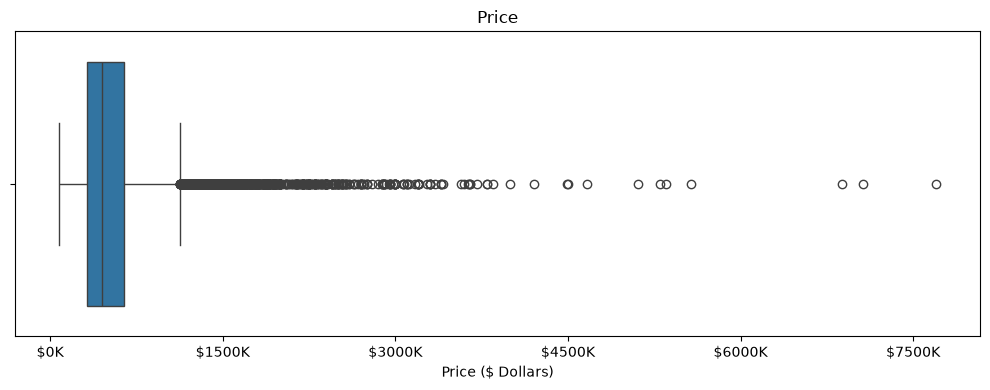

In [29]:
# intial boxplot to identify existing outliers 
df_clean["price"] = pd.to_numeric(
    df_clean["price"].astype(str).str.replace(r"[$,]", "", regex=True),
    errors="coerce"
)

fig, ax = plt.subplots(figsize=(10, 4))

sns.boxplot(x=df_clean["price"], ax=ax)

ax.set_title("Price")
ax.set_xlabel("Price ($ Dollars)")

# Format tick labels as $65K
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"${x/1000:.0f}K"))

# Limit to roughly 8 ticks
ax.xaxis.set_major_locator(MaxNLocator(nbins=8))

plt.tight_layout()
plt.show()

NameError: name 'k_format' is not defined

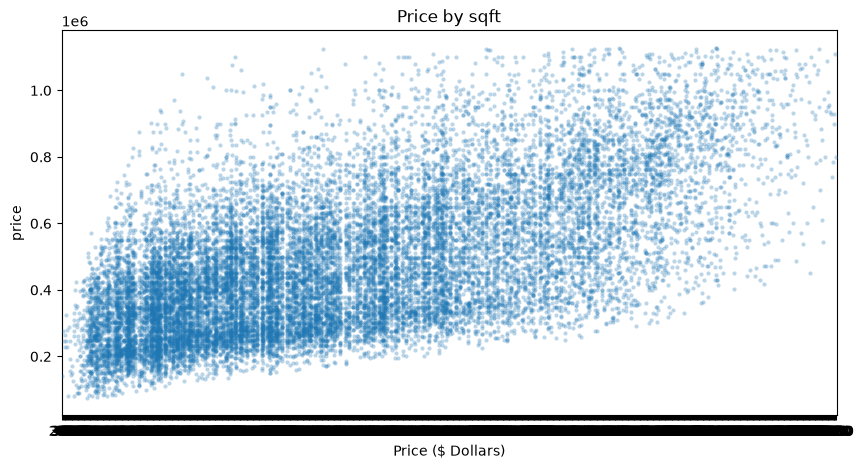

In [32]:
fig, ax = plt.subplots(figsize=(10, 5))

sns.stripplot(data=df_clean, x="sqft_living", y="price", jitter=0.3, alpha=0.3, size=3, ax=ax)

ax.set_title("Price by sqft")
ax.set_xlabel("Price ($ Dollars)")
ax.xaxis.set_major_formatter(k_format)

plt.tight_layout()
plt.show()

In [30]:
# following IQR rule finding the outliers
price = df_clean["price"]

# IQR rule
q1, q3 = price.quantile([0.25, 0.75])
iqr = q3 - q1
iqr_outliers = (price < q1 - 1.5 * iqr) | (price > q3 + 1.5 * iqr)
df_clean = df_clean[~iqr_outliers].reset_index(drop=True)
print(f"IQR rule:        keep {q1 - 1.5 * iqr:,.1f} to {q3 + 1.5 * iqr:,.1f} Dollars -> removes {iqr_outliers.sum():,} listings")

IQR rule:        keep -162,625.0 to 1,129,575.0 Dollars -> removes 1,146 listings


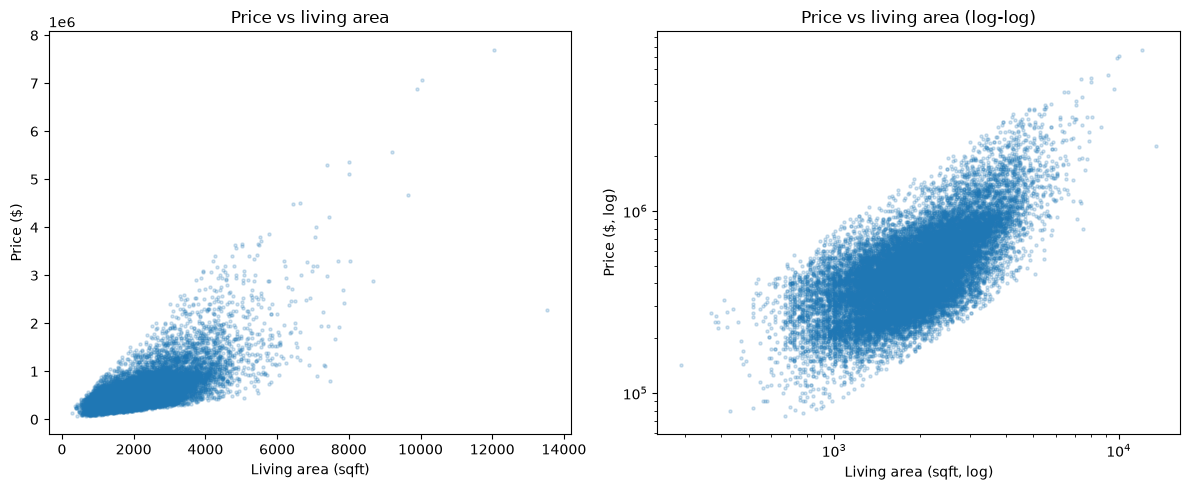

Correlation: 0.7


In [33]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Raw scale
axes[0].scatter(df["sqft_living"], df["price"], alpha=0.2, s=5)
axes[0].set_xlabel("Living area (sqft)")
axes[0].set_ylabel("Price ($)")
axes[0].set_title("Price vs living area")

# Log scale: spreads out the skewed price values
axes[1].scatter(df["sqft_living"], df["price"], alpha=0.2, s=5)
axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_xlabel("Living area (sqft, log)")
axes[1].set_ylabel("Price ($, log)")
axes[1].set_title("Price vs living area (log-log)")

plt.tight_layout()
plt.show()

print("Correlation:", df["sqft_living"].corr(df["price"]).round(2))

In [34]:
print(df[(df["bedrooms"] > 10) | (df["bedrooms"] == 0) | (df["bathrooms"] == 0)]
      [["price", "bedrooms", "bathrooms", "sqft_living"]])

           price  bedrooms  bathrooms  sqft_living
875    1095000.0         0       0.00         3064
1149     75000.0         1       0.00          670
3119    380000.0         0       0.00         1470
3467    288000.0         0       1.50         1430
4868    228000.0         0       1.00          390
5832    280000.0         1       0.00          600
6994   1295650.0         0       0.00         4810
8477    339950.0         0       2.50         2290
8484    240000.0         0       2.50         1810
8757    520000.0        11       3.00         3000
9773    355000.0         0       0.00         2460
9854    235000.0         0       0.00         1470
10481   484000.0         1       0.00          690
12653   320000.0         0       2.50         1490
14423   139950.0         0       0.00          844
15870   640000.0        33       1.75         1620
18379   265000.0         0       0.75          384
19452   142000.0         0       0.00          290


In [35]:
bad_rows = (df["bedrooms"] > 10) | (df["bedrooms"] == 0) | (df["bathrooms"] == 0)

print("Rows before:", len(df))
df = df[~bad_rows].reset_index(drop=True)
print("Rows after:", len(df))

Rows before: 21613
Rows after: 21595


In [36]:
# resetting the index
df_clean = df.reset_index(drop=True)

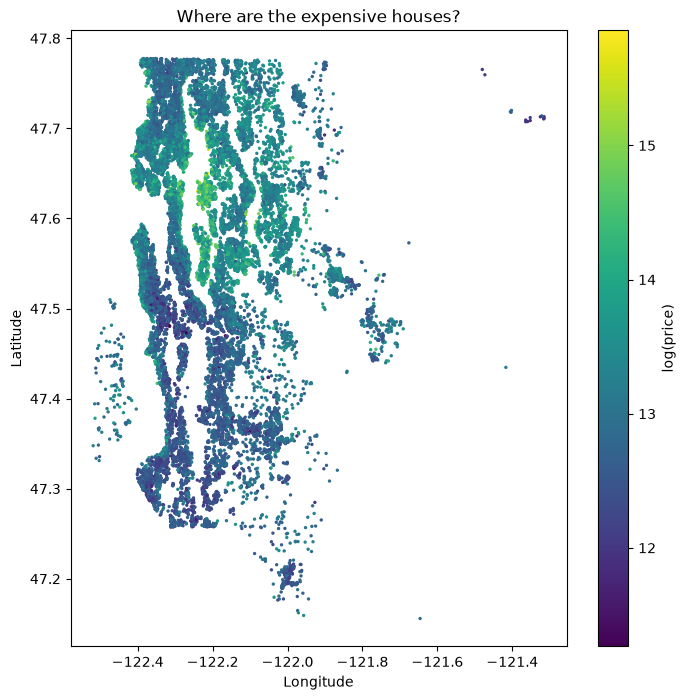

In [38]:
df["log_price"] = np.log(df["price"])
df["price_per_sqft"] = df["price"] / df["sqft_living"]

# 1. Map of Seattle from the data
plt.figure(figsize=(8, 8))
plt.scatter(df["long"], df["lat"], c=df["log_price"], cmap="viridis", s=2)
plt.colorbar(label="log(price)")
plt.title("Where are the expensive houses?")
plt.xlabel("Longitude"); plt.ylabel("Latitude")
plt.show()



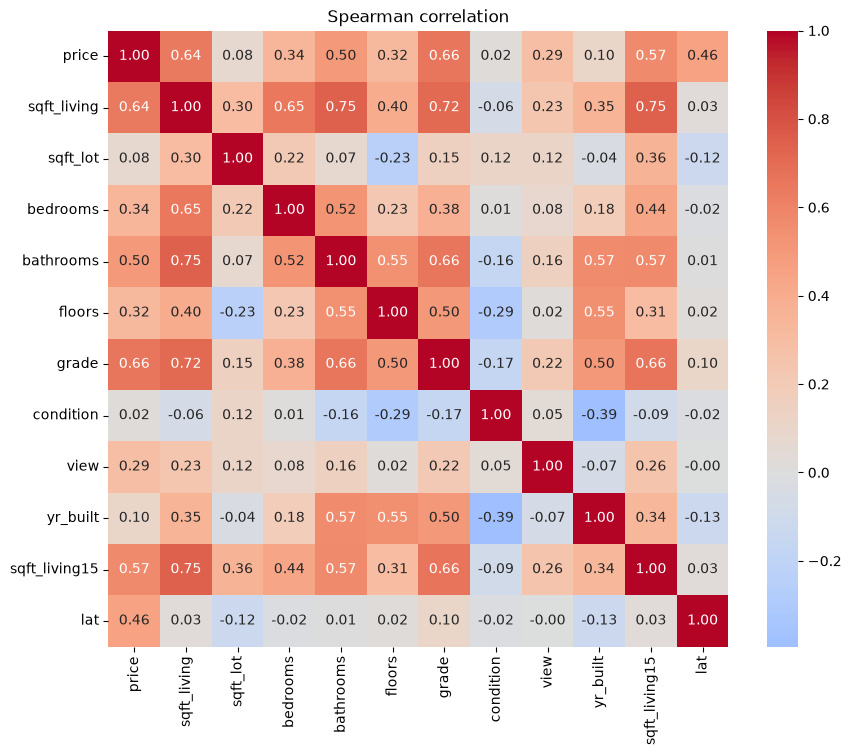

In [39]:
# 3. Spearman correlation heatmap
num_cols = ["price", "sqft_living", "sqft_lot", "bedrooms", "bathrooms", "floors",
            "grade", "condition", "view", "yr_built", "sqft_living15", "lat"]
plt.figure(figsize=(10, 8))
sns.heatmap(df[num_cols].corr(method="spearman"), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Spearman correlation")
plt.show()

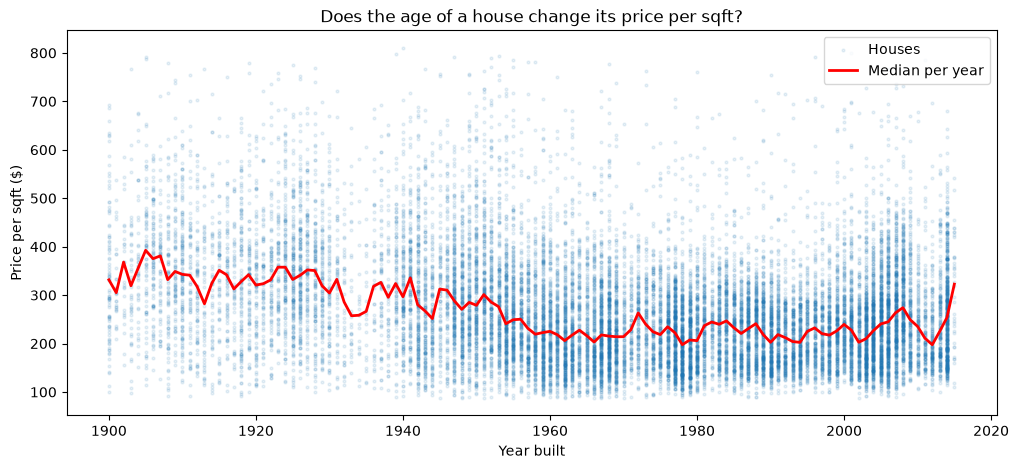

In [40]:
df["price_per_sqft"] = df["price"] / df["sqft_living"]


# 1. Year built vs price per sqft
median_by_year = df.groupby("yr_built")["price_per_sqft"].median()

plt.figure(figsize=(12, 5))
plt.scatter(df["yr_built"], df["price_per_sqft"], alpha=0.1, s=4, label="Houses")
plt.plot(median_by_year.index, median_by_year.values, color="red", linewidth=2, label="Median per year")
plt.xlabel("Year built")
plt.ylabel("Price per sqft ($)")
plt.title("Does the age of a house change its price per sqft?")
plt.legend()
plt.show()

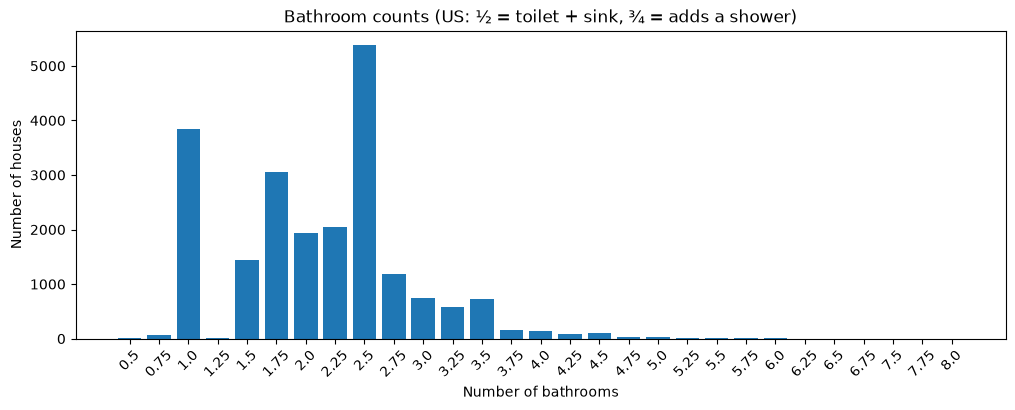

In [41]:
# 2. Bathrooms value counts
bath_counts = df["bathrooms"].value_counts().sort_index()

plt.figure(figsize=(12, 4))
plt.bar(bath_counts.index.astype(str), bath_counts.values)
plt.xlabel("Number of bathrooms")
plt.ylabel("Number of houses")
plt.title("Bathroom counts (US: ½ = toilet + sink, ¾ = adds a shower)")
plt.xticks(rotation=45)
plt.show()

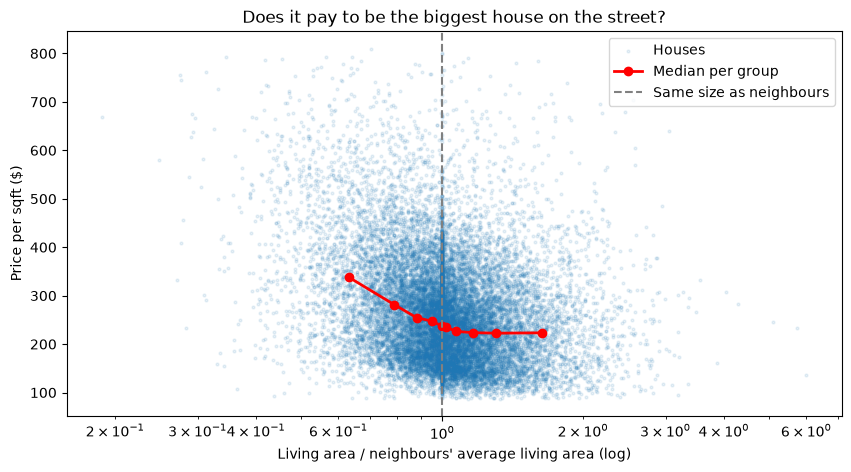

In [42]:
# 3. Bigger than the neighbours?
df["size_vs_neighbours"] = df["sqft_living"] / df["sqft_living15"]

# Median price per sqft within 10 equal-sized groups of the ratio
df["ratio_bin"] = pd.qcut(df["size_vs_neighbours"], q=10)
binned = df.groupby("ratio_bin", observed=True).agg(
    ratio=("size_vs_neighbours", "median"),
    ppsf=("price_per_sqft", "median"))

plt.figure(figsize=(10, 5))
plt.scatter(df["size_vs_neighbours"], df["price_per_sqft"], alpha=0.1, s=4, label="Houses")
plt.plot(binned["ratio"], binned["ppsf"], color="red", marker="o", linewidth=2, label="Median per group")
plt.axvline(1, color="grey", linestyle="--", label="Same size as neighbours")
plt.xscale("log")
plt.xlabel("Living area / neighbours' average living area (log)")
plt.ylabel("Price per sqft ($)")
plt.title("Does it pay to be the biggest house on the street?")
plt.legend()
plt.show()

df = df.drop(columns="ratio_bin")

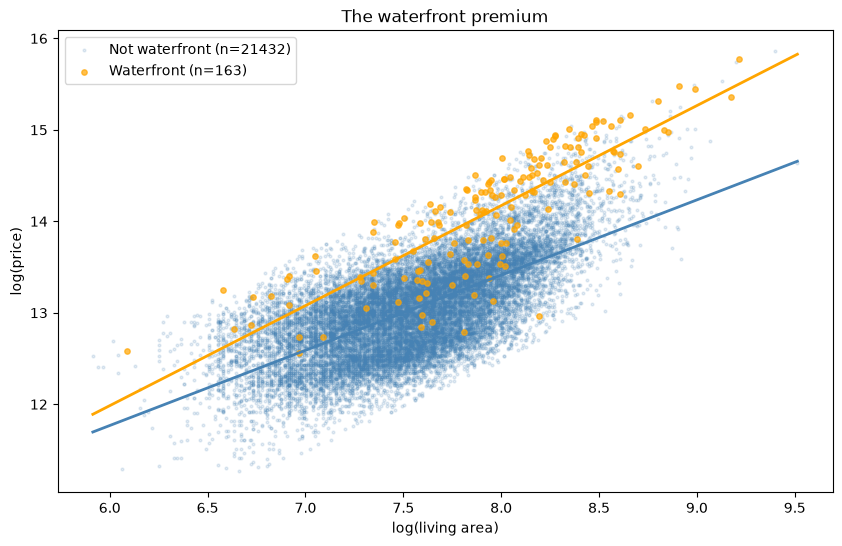

In [43]:
# 4. Price vs sqft, split by waterfront
df["log_price"] = np.log(df["price"])
df["log_sqft"] = np.log(df["sqft_living"])

plt.figure(figsize=(10, 6))
for value, color, label in [(0, "steelblue", "Not waterfront"), (1, "orange", "Waterfront")]:
    subset = df[df["waterfront"] == value]
    plt.scatter(subset["log_sqft"], subset["log_price"], alpha=0.15 if value == 0 else 0.7,
                s=4 if value == 0 else 15, color=color, label=f"{label} (n={len(subset)})")
    slope, intercept = np.polyfit(subset["log_sqft"], subset["log_price"], 1)
    x = np.linspace(df["log_sqft"].min(), df["log_sqft"].max(), 100)
    plt.plot(x, slope * x + intercept, color=color, linewidth=2)

plt.xlabel("log(living area)")
plt.ylabel("log(price)")
plt.title("The waterfront premium")
plt.legend()
plt.show()

In [ ]:
#hello world